# PROVISIONAL — Partition A trial results

> **NOT FINAL PROJECT RESULTS.** Yinkui draft annotations only, before Hayden’s adjudication and Becca’s finalized preparation. All scores are development validation results; no final test evaluation.

This notebook displays the completed run and verifies saved metrics. Training commands are in README.md. The team will rerun on the reviewed dataset.

In [1]:
from pathlib import Path
import json, hashlib
import pandas as pd
from IPython.display import display, Markdown, Image
RUN = Path('.')
read = lambda name: json.loads((RUN/name).read_text(encoding='utf8'))
provenance = read('data_provenance.json')
assert hashlib.sha256((RUN/'dataset_development.jsonl').read_bytes()).hexdigest() == provenance['data_sha256']
rows = [json.loads(s) for s in (RUN/'dataset_development.jsonl').read_text(encoding='utf8').splitlines()]
assert {r['period'] for r in rows} == {'train', 'validation'}
display(pd.DataFrame(read('dataset_summary.json')['split_class_counts']).T.rename(columns={'0':'affirmed','1':'reversed/vacated'}))

,affirmed,reversed/vacated
train,62,27
validation,8,8
test,12,5


## Feedback 1: masking audit before modeling
Two cases per class in each development split. Human review remains pending; collateral deletion is a documented limitation.

In [2]:
display(Markdown((RUN/'MASKING_AUDIT_REVIEW.md').read_text(encoding='utf8')))

# Pre-model masking audit — assistant review, not human approval

Reviewed on 2026-10-23 against the full cleaned opinions and the removed sentences in MASKING_AUDIT_PACKET.md, before fitting any models. Two seeded cases per class per development split: eight opinions total. Training examples informed a repair to judicial-concurrence footer removal. The four validation examples were inspected after that repair; their findings below did not change the masking rules. No test opinion was inspected for this audit. Reviewer: the coding assistant; human review remains pending.

The target is the whole current appeal's affirmed/reversed outcome, not who won the original motion. Historical lower-court rulings and cited precedents should remain. Removing the final disposition does not turn a published opinion into a pre-decision prediction task: judicial reasoning itself can strongly imply the answer.

| Case | Split / label | Current whole-appeal outcome | Useful reasoning / earlier decisions | Assessment |
|---|---|---|---|---|
| NY-4394527, Fellner | Training / 0 | Opening affirmance removed | Surveillance and notice reasoning remain; earlier appeal dismissal and Bray/Cox references remain | Pass on sampled criteria |
| NY-6004283, Germain | Training / 0 | Operative affirmance and express approval of appealed ruling removed | Rug dimensions, trivial-defect reasoning and expert evidence remain; historical grant of summary judgment retained | Pass on sampled criteria; some reasoning is lost with the approval sentence |
| NY-5934687, Williams | Training / 1 | Ordered reversal and repeated motion disposition removed | Mat, creation/notice, proof and precedents remain; original denial retained | Pass on sampled criteria |
| NY-4253165, Keum Ok Han | Training / 1 | Ordered reversal and concluding should-have-granted sentence removed | Out-of-possession and notice reasoning and earlier trial ruling remain | Pass on sampled criteria |
| NY-9355453, Cheprakova | Validation / 0 | Operative affirmance and concluding approval removed | Causation, speculation, surveillance and precedents remain; the historical grant remains in a later sentence | Partial: sentence segmentation joins the first historical ruling ending in “Inc.” to the Ordered sentence, so some history is unnecessarily removed |
| NY-5302167, Luttenberger | Validation / 0 | Operative affirmance and concluding approval removed | Threshold facts, open/obvious reasoning, precedents and earlier motion disposition remain | Pass on sampled criteria |
| NY-4929051, Zubillaga | Validation / 1 | Both opening reversed orders removed | Extensive warning-sign and notice reasoning and earlier default rulings retained | Whole-appeal target removed, but current leave-to-appeal and ancillary motion results remain. Hayden should confirm eligibility for this procedural-plus-merits, multiple-order opinion |
| NY-7857572, Yerry | Validation / 1 | Ordered reversal and concluding should-have-denied sentence removed | Notice/remedial-measure reasoning, earlier ruling and many precedents remain | Partial: “Supreme Court properly considered” also removes an evidentiary ruling and its precedents, although it does not state the whole appeal's result |

All eight sampled whole-appeal dispositions were removed; this is not a corpus-wide leakage clearance. Six had no material failure on the specified sampled criteria, while two show avoidable collateral removal. Zubillaga additionally illustrates the need to define the boundary for ancillary procedural outcomes. These are qualitative observations, not an estimate of masking accuracy.

## Training-set outliers, inspected separately

- NY-5936535: 85 of 149 words (57.0%) removed. The opinion is extremely short; its final sentence combines direct appellate approval, reasoning and precedents. Whole-sentence removal retains basic accident facts but loses most of the explanation. Flag for human review, not automatic exclusion.
- NY-4619223: more than 30% removed, including an introductory summary-judgment sentence that also contains accident context. Flag for human review. The initial excerpt was inspected; do not count this as a full semantic review of that opinion.

## Frozen prototype decision

Run the present rules unchanged, retain all included development cases, and report these limitations. The five matched-word-budget random-removal runs are central to interpretation. This trial is a diagnostic of the masking strategy, not evidence that a final mask is ready. Becca and Hayden should review collateral loss and residual cues using development opinions before finalizing the production pipeline. Any revision must have a new mask version/run name and a rerun of all conditions; do not use test outcomes to revise rules.


## Fixed-C experiments and the random-removal control
Fixed C=1 isolates the text intervention. Seed variability is not a confidence interval.

,model,variant,C,accuracy,balanced_accuracy,macro_f1,confusion_matrix,class_counts
0,Majority,FULL,NaN,0.5000,0.5000,0.333333,"[[8, 0], [8, 0]]","{'0': 8, '1': 8}"
1,TFIDF_LR,FULL,1.0,0.6875,0.6875,0.676113,"[[7, 1], [4, 4]]","{'0': 8, '1': 8}"
2,TFIDF_LR,MASKED,1.0,0.6250,0.6250,0.600000,"[[7, 1], [5, 3]]","{'0': 8, '1': 8}"
3,TFIDF_LR,RANDOM_11,1.0,0.6250,0.6250,0.600000,"[[7, 1], [5, 3]]","{'0': 8, '1': 8}"
4,TFIDF_LR,RANDOM_23,1.0,0.6875,0.6875,0.676113,"[[7, 1], [4, 4]]","{'0': 8, '1': 8}"
5,TFIDF_LR,RANDOM_37,1.0,0.6250,0.6250,0.600000,"[[7, 1], [5, 3]]","{'0': 8, '1': 8}"
6,TFIDF_LR,RANDOM_51,1.0,0.7500,0.7500,0.746032,"[[7, 1], [3, 5]]","{'0': 8, '1': 8}"
7,TFIDF_LR,RANDOM_71,1.0,0.6875,0.6875,0.676113,"[[7, 1], [4, 4]]","{'0': 8, '1': 8}"
8,TFIDF_SVM,FULL,1.0,0.7500,0.7500,0.733333,"[[8, 0], [4, 4]]","{'0': 8, '1': 8}"
9,TFIDF_SVM,MASKED,1.0,0.5000,0.5000,0.418182,"[[7, 1], [7, 1]]","{'0': 8, '1': 8}"


,mean,sd_across_seeds,values
accuracy,0.675,0.052291,"[0.625, 0.6875, 0.625, 0.75, 0.6875]"
balanced_accuracy,0.675,0.052291,"[0.625, 0.6875, 0.625, 0.75, 0.6875]"
macro_f1,0.659652,0.061482,"[0.6, 0.6761133603238867, 0.6, 0.7460317460317..."


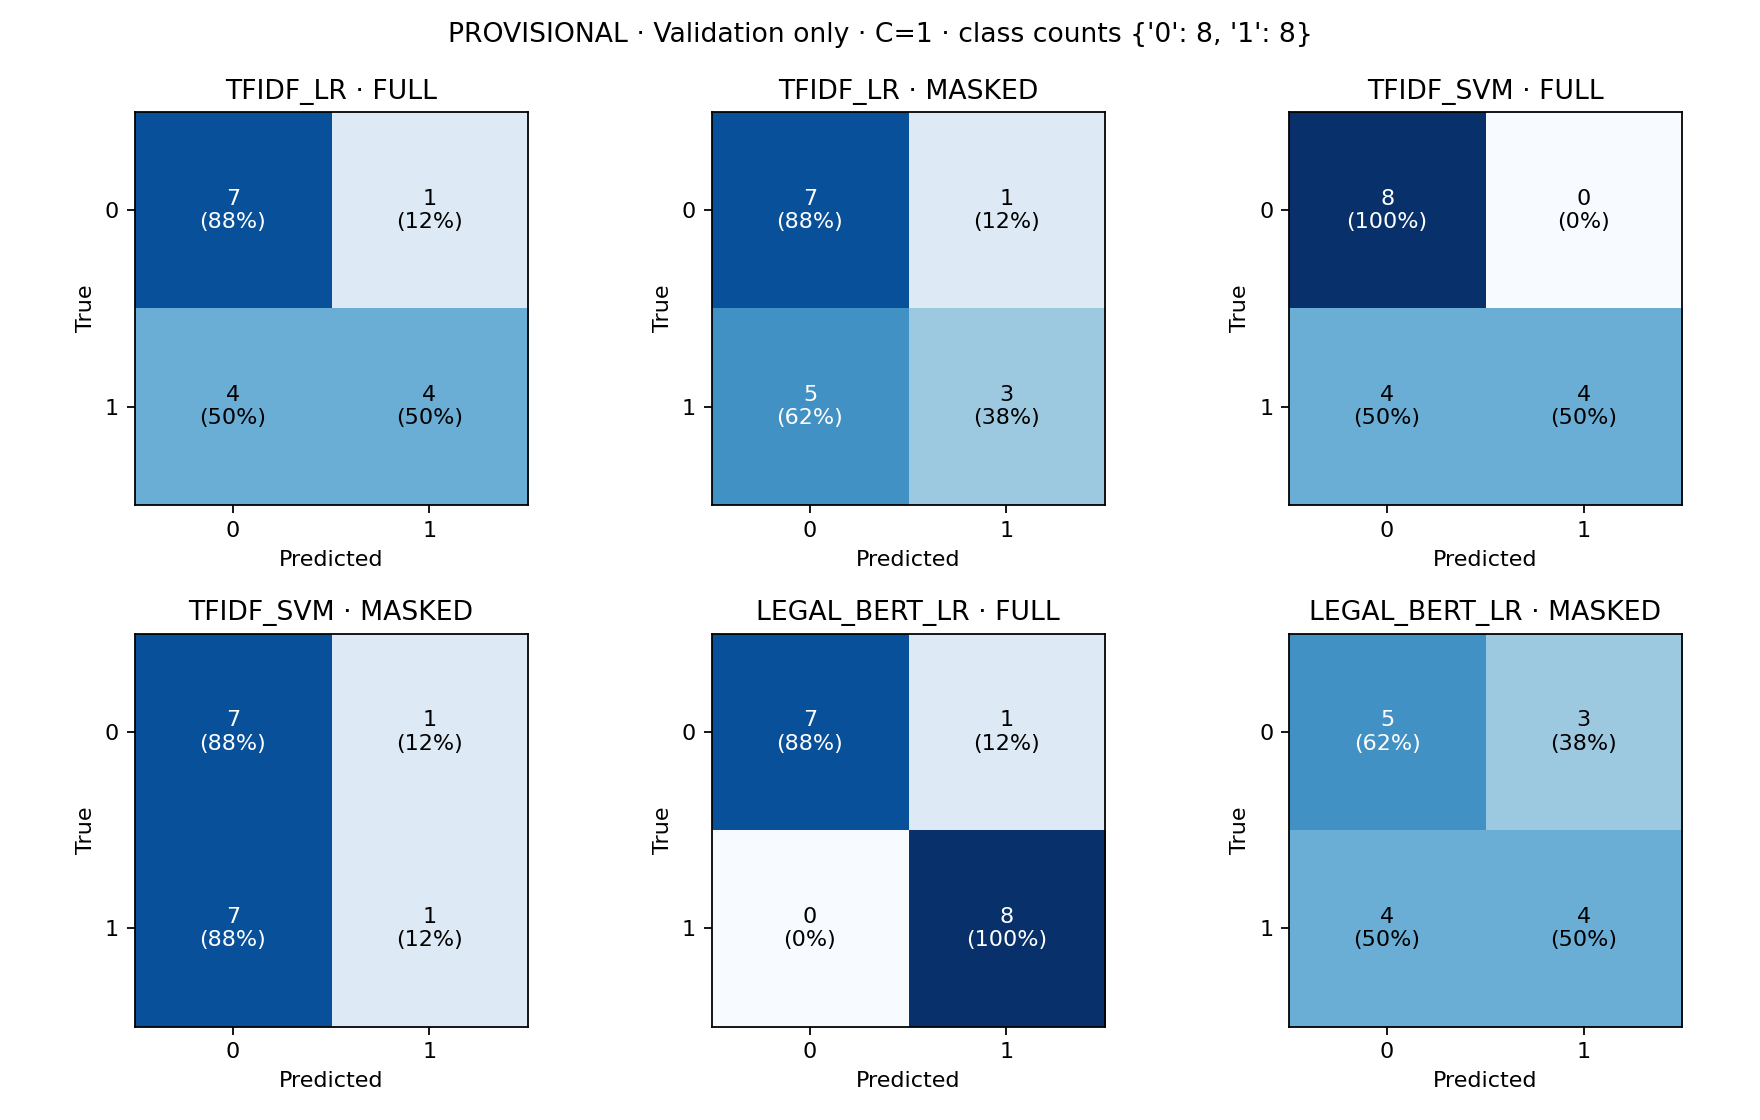

In [3]:
results=read('metrics.json')
columns=['model','variant','C','accuracy','balanced_accuracy','macro_f1','confusion_matrix','class_counts']
display(pd.DataFrame(results['controlled'])[columns])
display(pd.DataFrame(results['random_control_fixed_C']).T)
display(Image(filename=str(RUN/'plots/confusion_matrices.png')))

## Proposal C-grid selection
Validation was also used to choose C; these are development scores, not independent test estimates.

In [4]:
display(pd.DataFrame(results['selected_on_validation'])[columns])

,model,variant,C,accuracy,balanced_accuracy,macro_f1,confusion_matrix,class_counts
0,LEGAL_BERT_LR,FULL,1.0,0.9375,0.9375,0.937255,"[[7, 1], [0, 8]]","{'0': 8, '1': 8}"
1,LEGAL_BERT_LR,MASKED,1.0,0.5625,0.5625,0.560784,"[[5, 3], [4, 4]]","{'0': 8, '1': 8}"
2,Majority,FULL,NaN,0.5000,0.5000,0.333333,"[[8, 0], [8, 0]]","{'0': 8, '1': 8}"
3,TFIDF_LR,FULL,10.0,0.7500,0.7500,0.733333,"[[8, 0], [4, 4]]","{'0': 8, '1': 8}"
4,TFIDF_LR,MASKED,1.0,0.6250,0.6250,0.600000,"[[7, 1], [5, 3]]","{'0': 8, '1': 8}"
5,TFIDF_LR,RANDOM_11,10.0,0.6875,0.6875,0.653680,"[[8, 0], [5, 3]]","{'0': 8, '1': 8}"
6,TFIDF_LR,RANDOM_23,10.0,0.7500,0.7500,0.733333,"[[8, 0], [4, 4]]","{'0': 8, '1': 8}"
7,TFIDF_LR,RANDOM_37,1.0,0.6250,0.6250,0.600000,"[[7, 1], [5, 3]]","{'0': 8, '1': 8}"
8,TFIDF_LR,RANDOM_51,1.0,0.7500,0.7500,0.746032,"[[7, 1], [3, 5]]","{'0': 8, '1': 8}"
9,TFIDF_LR,RANDOM_71,10.0,0.7500,0.7500,0.733333,"[[8, 0], [4, 4]]","{'0': 8, '1': 8}"


## Lengths and frozen encoder
Every chunk contributes. Word lengths and token lengths are different measurements.

In [5]:
lengths=[]
for split, variants in read('dataset_summary.json')['word_lengths'].items():
    for variant, stats in variants.items(): lengths.append(dict(split=split,variant=variant,**stats))
display(pd.DataFrame(lengths))
tokens=[]
for variant, splits in read('token_length_statistics.json').items():
    for split, stats in splits.items(): tokens.append(dict(split=split,variant=variant,**stats))
display(pd.DataFrame(tokens))

,split,variant,n,min,median,mean,p90,max
0,train,FULL,89,86.0,468.0,516.685393,843.0,1495.0
1,train,MASKED,89,64.0,428.0,475.977528,805.2,1434.0
2,validation,FULL,16,276.0,534.0,650.875000,925.5,1796.0
3,validation,MASKED,16,250.0,466.0,588.687500,872.0,1671.0


,split,variant,n,min,median,mean,p90,max,fraction_over_510,total_chunks
0,train,FULL,89,113.0,642.0,710.359551,1189.2,1900.0,0.662921,163
1,validation,FULL,16,375.0,714.0,868.250000,1252.0,2320.0,0.875000,36
2,train,MASKED,89,82.0,593.0,656.775281,1128.0,1810.0,0.640449,161
3,validation,MASKED,16,331.0,634.5,785.687500,1208.0,2147.0,0.812500,35


## Independently recompute all saved validation metrics

In [6]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix
predictions=[json.loads(s) for s in (RUN/'validation_predictions.jsonl').read_text(encoding='utf8').splitlines()]
expected={r['case_id'] for r in rows if r['period']=='validation'}
for result in results['grid']:
    p=[p for p in predictions if (p['model'],p['variant'],p['C'])==(result['model'],result['variant'],result['C'])]
    assert {x['case_id'] for x in p}==expected
    y=[x['true_label'] for x in p]; yp=[x['predicted_label'] for x in p]
    assert accuracy_score(y,yp)==result['accuracy']
    assert balanced_accuracy_score(y,yp)==result['balanced_accuracy']
    assert f1_score(y,yp,average='macro',labels=[0,1],zero_division=0)==result['macro_f1']
    assert confusion_matrix(y,yp,labels=[0,1]).tolist()==result['confusion_matrix']
print(f"Verified {len(results['grid'])} model/C conditions on the same {len(expected)} validation cases; no test predictions.")

Verified 34 model/C conditions on the same 16 validation cases; no test predictions.


## Findings and next iteration

In [7]:
display(Markdown((RUN/'REPORT.md').read_text(encoding='utf8')))

# PROVISIONAL — Partition A trial results

> **NOT FINAL PROJECT RESULTS.** Development run only; label and dataset review are not certified by this report. For the original Yinkui trial, Hayden’s adjudication and Becca’s final preparation are pending. Do not interpret these scores as final test performance or a reliable model ranking.

Run: yinkui_A_provisional_v1. Input annotations: annotation/submissions/yinkui/batches/A/annotations.jsonl. Uses only Yinkui’s frozen independent LLM-draft annotations, not adjudicated human ground truth. All scores below are DEVELOPMENT validation scores. No test text is passed to preprocessing/feature extraction/model evaluation; only test metadata/counts and unsupervised family screening are used.

## Dataset and split

169 candidate decisions: 122 marked include, 36 pending review, 11 excluded. Modeling status counts: {'sealed_test': 17, 'included': 105, 'review': 36, 'exclude': 11}. The family screen does not certify complete family resolution.

| Period | Use | Affirmed (0) | Reversed/vacated (1) | Total |
|---|---|---:|---:|---:|
| 2010–2020 | Training | 62 | 27 | 89 |
| 2021–2022 | Validation | 8 | 8 | 16 |
| 2023–2024 | Sealed test | 12 | 5 | 17 |

One validation error changes accuracy by 6.25 percentage points. Accuracy and balanced accuracy coincide only if the validation classes are balanced. This set is also used for C selection, so tuned scores are not independent performance estimates. Check the reviewed case count against the proposal’s 150-reviewed-case MVP target and 300-eligible-case threshold for stronger final conclusions.

## Main controlled experiment

Fix C=1 in advance for all learned conditions to isolate text changes. Class weights, vocabulary/IDF and BERT feature scaling are fitted using training data only. Confusion matrices use true rows and predicted columns in order [0, 1]. Full per-class recall and row-normalized matrices are in metrics.json and the notebook.

| Model | Text | C | Accuracy | Balanced accuracy | Macro F1 | Confusion matrix |
|---|---|---:|---:|---:|---:|---|
| Majority | FULL | None | 0.500 | 0.500 | 0.333 | [[8, 0], [8, 0]] |
| TFIDF_LR | FULL | 1.0 | 0.688 | 0.688 | 0.676 | [[7, 1], [4, 4]] |
| TFIDF_LR | MASKED | 1.0 | 0.625 | 0.625 | 0.600 | [[7, 1], [5, 3]] |
| TFIDF_SVM | FULL | 1.0 | 0.750 | 0.750 | 0.733 | [[8, 0], [4, 4]] |
| TFIDF_SVM | MASKED | 1.0 | 0.500 | 0.500 | 0.418 | [[7, 1], [7, 1]] |
| LEGAL_BERT_LR | FULL | 1.0 | 0.938 | 0.938 | 0.937 | [[7, 1], [0, 8]] |
| LEGAL_BERT_LR | MASKED | 1.0 | 0.562 | 0.562 | 0.561 | [[5, 3], [4, 4]] |

## Matched-length random-removal control (main LR experiment)

Five fixed seeds, uniform sentence removal order, with a random contiguous portion of the final sentence when needed to exactly match each opinion’s masked word-loss budget. Outcome sentences remain eligible for random removal. This is a word-budget control, not a matched BERT-token or matched semantic-content control. No seed is selected as the winner.

| Model | Text | C | Accuracy | Balanced accuracy | Macro F1 | Confusion matrix |
|---|---|---:|---:|---:|---:|---|
| TFIDF_LR | RANDOM_11 | 1.0 | 0.625 | 0.625 | 0.600 | [[7, 1], [5, 3]] |
| TFIDF_LR | RANDOM_23 | 1.0 | 0.688 | 0.688 | 0.676 | [[7, 1], [4, 4]] |
| TFIDF_LR | RANDOM_37 | 1.0 | 0.625 | 0.625 | 0.600 | [[7, 1], [5, 3]] |
| TFIDF_LR | RANDOM_51 | 1.0 | 0.750 | 0.750 | 0.746 | [[7, 1], [3, 5]] |
| TFIDF_LR | RANDOM_71 | 1.0 | 0.688 | 0.688 | 0.676 | [[7, 1], [4, 4]] |

- accuracy: 0.675 ± 0.052 (sample standard deviation across five seeds, not a confidence interval).

- balanced_accuracy: 0.675 ± 0.052 (sample standard deviation across five seeds, not a confidence interval).

- macro_f1: 0.660 ± 0.061 (sample standard deviation across five seeds, not a confidence interval).

At fixed C, LR balanced accuracy changes from 0.688 (FULL) to 0.625 (MASKED); the random-removal mean is 0.675. The differences describe this tiny provisional validation sample. They do not identify a causal effect of outcome language: masking also removes some useful reasoning, and random removal can itself remove outcome cues.

## Proposal-specified hyperparameter search (secondary)

C ∈ {0.1, 1, 10}; maximize validation balanced accuracy, then macro F1, then smaller C. These are scores on the same validation set used for selection, not final test scores. Compare the fixed-C results above when isolating the masking effect.

| Model | Text | C | Accuracy | Balanced accuracy | Macro F1 | Confusion matrix |
|---|---|---:|---:|---:|---:|---|
| LEGAL_BERT_LR | FULL | 1.0 | 0.938 | 0.938 | 0.937 | [[7, 1], [0, 8]] |
| LEGAL_BERT_LR | MASKED | 1.0 | 0.562 | 0.562 | 0.561 | [[5, 3], [4, 4]] |
| Majority | FULL | None | 0.500 | 0.500 | 0.333 | [[8, 0], [8, 0]] |
| TFIDF_LR | FULL | 10.0 | 0.750 | 0.750 | 0.733 | [[8, 0], [4, 4]] |
| TFIDF_LR | MASKED | 1.0 | 0.625 | 0.625 | 0.600 | [[7, 1], [5, 3]] |
| TFIDF_LR | RANDOM_11 | 10.0 | 0.688 | 0.688 | 0.654 | [[8, 0], [5, 3]] |
| TFIDF_LR | RANDOM_23 | 10.0 | 0.750 | 0.750 | 0.733 | [[8, 0], [4, 4]] |
| TFIDF_LR | RANDOM_37 | 1.0 | 0.625 | 0.625 | 0.600 | [[7, 1], [5, 3]] |
| TFIDF_LR | RANDOM_51 | 1.0 | 0.750 | 0.750 | 0.746 | [[7, 1], [3, 5]] |
| TFIDF_LR | RANDOM_71 | 10.0 | 0.750 | 0.750 | 0.733 | [[8, 0], [4, 4]] |
| TFIDF_SVM | FULL | 1.0 | 0.750 | 0.750 | 0.733 | [[8, 0], [4, 4]] |
| TFIDF_SVM | MASKED | 0.1 | 0.625 | 0.625 | 0.600 | [[7, 1], [5, 3]] |

## Masking audit and professor feedback

See the run-specific MASKING_AUDIT_REVIEW.md and MASKING_AUDIT_PACKET.md. The sampling design includes both classes in training and validation. Review outcome removal, retained reasoning and historical decisions before fitting; record the actual reviewer and findings. An assistant check is not human approval.

For the original yinkui_A_provisional_v1 run, all eight sampled whole-appeal dispositions were removed, but two validation opinions showed collateral deletion and a training outlier lost 57% of its words. One sampled opinion retained ancillary procedural results. Those validation findings were recorded without changing rules. New runs require a fresh audit rather than inheriting these observations. The audit and five-seed random-removal control implement both feedback requests.

## Text lengths

| Split | Text | Minimum words | Median | Mean | P90 | Maximum |
|---|---|---:|---:|---:|---:|---:|
| train | FULL | 86 | 468.0 | 516.7 | 843.0 | 1495 |
| train | MASKED | 64 | 428.0 | 476.0 | 805.2 | 1434 |
| validation | FULL | 276 | 534.0 | 650.9 | 925.5 | 1796 |
| validation | MASKED | 250 | 466.0 | 588.7 | 872.0 | 1671 |

Masking removes a mean 9.6% of words per opinion (median 8.3%, maximum 57.0%). The historical dataset_summary.json key `removed_fraction` contains percentage statistics; individual dataset rows contain true fractions.


| Split | Text | Min tokens | Median | Mean | P90 | Max | >510 content tokens | Total chunks |
|---|---|---:|---:|---:|---:|---:|---:|---:|
| train | FULL | 113 | 642.0 | 710.4 | 1189.2 | 1900 | 66.3% | 163 |
| validation | FULL | 375 | 714.0 | 868.2 | 1252.0 | 2320 | 87.5% | 36 |
| train | MASKED | 82 | 593.0 | 656.8 | 1128.0 | 1810 | 64.0% | 161 |
| validation | MASKED | 331 | 634.5 | 785.7 | 1208.0 | 2147 | 81.2% | 35 |

LEGAL-BERT uses every non-overlapping chunk of up to 510 content tokens plus CLS/SEP. Padding and special tokens are excluded from mean pooling. Chunk vectors are averaged with content-token-count weights; no first-512 truncation and no fine-tuning.

## Error analysis and next review

ERROR_REVIEW_PACKET.md includes all 16 validation opinions, their original source links, FULL/MASKED LR and cross-model predictions, removed passages, and masked text. This is a review queue, not a claim that every error has been legally adjudicated. The original run also has ERROR_OBSERVATIONS.md with four assistant-reviewed examples. Automatic length-group summaries are in subgroup_metrics.json; each bin’s class counts must accompany its scores.

tfidf_features.json lists training-derived positive/negative coefficients at C=1. Coefficients are diagnostic associations, not explanations of legal causation. Because validation is small, no claim that LEGAL-BERT is superior is justified by one run.

Hayden: confirm eligibility and labels independently of these predictions, especially procedural-plus-merits and ambiguous property cases; preserve disagreements. Becca: finalize case families, source cleanup and masks, inspect collateral removal and residual cues, and freeze the reviewed dataset. Yinkui: rerun all conditions under a new run name on that dataset. Keep the test period sealed until the final pipeline and evaluation labels are fixed.

For the final study, compute paired 95% bootstrap intervals using case families for test metrics and FULL-minus-MASKED differences. This prototype deliberately provides no test intervals or test metrics. Expand beyond A if stronger comparative conclusions are needed.


## Before the reviewed rerun
Hayden resolves eligibility/outcomes independently of model predictions; Becca freezes the reviewed dataset, families and masks; Yinkui reruns this grid under a new version. Do not interpret this run as human-ground-truth evaluation. No final-test analysis was performed. Paired family bootstrap intervals belong to the eventual final evaluation.